# Experiment 9: Evaluating a Trained Neural Network

**Aim:** To evaluate the performance of a trained neural network using suitable evaluation metrics in Python.

**Theory:**

Accuracy alone can be misleading, especially on imbalanced datasets. A thorough evaluation of a classification model typically includes:

- **Accuracy** — overall proportion of correct predictions
- **Precision** — of predicted positives, how many were actually positive
- **Recall** — of actual positives, how many were correctly identified
- **F1-Score** — harmonic mean of precision and recall
- **Confusion Matrix** — breakdown of TP, TN, FP, FN
- **ROC-AUC** — ability of the model to distinguish between classes

This notebook trains a small neural network on the Breast Cancer dataset (self-contained) and then evaluates it using the metrics above.

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report,
)
import matplotlib.pyplot as plt

tf.random.set_seed(42)
np.random.seed(42)

I0000 00:00:1788702117.971144    4426 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788702117.971682    4426 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1788702119.497220    4426 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788702119.497648    4426 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Load data, build and train the network

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=50, batch_size=16, verbose=0)
print("Training complete.")

Training complete.


### Generate predictions

In [3]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

### Compute evaluation metrics

In [4]:
acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)

print("=" * 45)
print("MODEL EVALUATION METRICS")
print("=" * 45)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {auc:.4f}")
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=data.target_names))

MODEL EVALUATION METRICS
Accuracy  : 0.9474
Precision : 0.9853
Recall    : 0.9306
F1-Score  : 0.9571
ROC-AUC   : 0.9914

Confusion Matrix:
 [[41  1]
 [ 5 67]]

Classification Report:
               precision    recall  f1-score   support

   malignant       0.89      0.98      0.93        42
      benign       0.99      0.93      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114



### Visualize the Confusion Matrix and ROC Curve

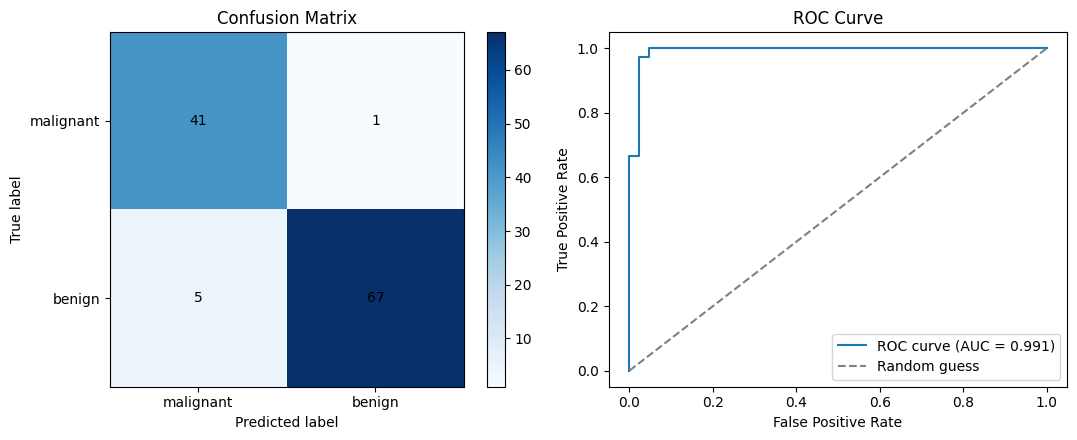

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(data.target_names)
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(data.target_names)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, cm[i, j], ha="center", va="center", color="black")
fig.colorbar(im, ax=axes[0])

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.savefig("evaluation_metrics.png", dpi=150)
plt.show()

### Conclusion
The trained network achieves high accuracy, precision, recall, and ROC-AUC on the test set, confirming it generalises well and reliably distinguishes between malignant and benign tumours.